# Folio: A Hybrid Book Recommender System
**Dataset:** Goodbooks-10k (≈980k ratings, 53k readers, 10k books, 34k user-assigned tags)

### Is this classification or recommendation?
This is a **recommender system**. The model does not assign a fixed label to an input. It **predicts how much a reader will like every book** (a 1–5 star score) and then **ranks** the books the reader has not read. We evaluate it in two ways:
* as a **rating-prediction** (regression) problem: RMSE / MAE on hidden ratings, and
* as a **top-K ranking** problem: Precision / Recall / NDCG / HitRate @10 over the whole catalogue, which is what users actually see.

### What this notebook covers
1. Data loading and cleaning (including fixing a **book-ID mismatch** in the first version)
2. Exploratory data analysis
3. Collaborative filtering two ways: **SVD** matrix factorisation (explicit star ratings, tuned and compared against baselines) and **item-kNN** on implicit co-reading
4. A **content-based** model built from Goodreads tags and authors (TF-IDF)
5. A **hybrid** model that blends all signals, tuned on validation users
6. Proper **full-catalogue ranking evaluation**
7. **Cold start**: recommendations for brand-new readers via fold-in
8. **Explainable** recommendations ("Because you liked …")
9. Exporting the model for the web app (`app.py`)

All the reusable code lives in the `recsys/` package, so this notebook and the web app use exactly the same implementation.

In [1]:
import json, sys, time
from pathlib import Path

# run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from recsys import data, features, pipeline, scoring, evaluation
from recsys.config import GENRES, TOP_K, RELEVANCE_THRESHOLD, RANDOM_STATE

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 70)

## 1. Load and clean the data

### The ID bug in the first version
The files use **two different book IDs**:

| file | column | meaning |
|---|---|---|
| `ratings.csv`, `to_read.csv` | `book_id` | 1…10000, which equals `books.csv` **`id`** |
| `books.csv` | `book_id` | the **Goodreads** ID (e.g. 2767052) |
| `book_tags.csv` | `goodreads_book_id` | the Goodreads ID |

The original `recommend_books()` scored `books["book_id"]` (Goodreads IDs) with a model trained on `ratings.book_id`. Only 812 Goodreads IDs fall in the range 1–10000, and those point to **different books**. The other ≈9,200 were unknown to the model, so it returned the global mean for them. The recommendations it printed were therefore effectively random.

In [2]:
raw_books = pd.read_csv(data.DATA_DIR / "books.csv")
raw_ratings = pd.read_csv(data.DATA_DIR / "ratings.csv")
print("ratings.book_id range:", raw_ratings.book_id.min(), "-", raw_ratings.book_id.max())
print("books.book_id (Goodreads) range:", raw_books.book_id.min(), "-", raw_books.book_id.max())
print()
print("ratings.book_id = 2767 is really ->", raw_books.loc[raw_books.id == 2767, "title"].item())
print("but books.book_id = 2767 is     ->", raw_books.loc[raw_books.book_id == 2767, "title"].item())
print("\nDuplicate (user, book) ratings:", raw_ratings.duplicated(["user_id", "book_id"]).sum())

ratings.book_id range: 1 - 10000
books.book_id (Goodreads) range: 1 - 33288638

ratings.book_id = 2767 is really -> Saga, Vol. 3 (Saga, #3)
but books.book_id = 2767 is     -> A People's History of the United States

Duplicate (user, book) ratings: 2278


`recsys.data` fixes this by renaming `books.id → book_id` and the Goodreads ID to `goodreads_book_id`, so every table joins on one key. It also averages the duplicate ratings and filters out "shelf" tags such as *to-read*, *owned* or *kindle*, which describe the reader's shelf rather than the book.

In [3]:
books, ratings, book_tags = pipeline.load_all()
to_read = data.load_to_read()

print(f"ratings: {len(ratings):,}   users: {ratings.user_id.nunique():,}   books: {len(books):,}")
print(f"tag assignments: {len(book_tags):,}  ({book_tags.noise.mean():.0%} flagged as shelf noise)")
print(f"to-read entries: {len(to_read):,}")
display(books[["book_id", "goodreads_book_id", "title", "authors", "year", "genres", "tags"]].head())

ratings: 979,478   users: 53,424   books: 10,000
tag assignments: 999,898  (43% flagged as shelf noise)
to-read entries: 912,705


,book_id,goodreads_book_id,title,authors,year,genres,tags
0,1,2767052,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2008,"[Young Adult, Dystopian, Science Fiction]","[young-adult, fiction, dystopian, dystopia, fantasy, ya, science-f..."
1,2,3,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",1997,"[Fantasy, Young Adult, Children's]","[fantasy, young-adult, fiction, harry-potter, ya, magic, childrens..."
2,3,41865,"Twilight (Twilight, #1)",Stephenie Meyer,2005,"[Young Adult, Paranormal, Fantasy]","[young-adult, fantasy, vampires, ya, fiction, paranormal, vampire,..."
3,4,2657,To Kill a Mockingbird,Harper Lee,1960,"[Classics, Historical Fiction]","[classics, classic, historical-fiction, literature, young-adult, h..."
4,5,4671,The Great Gatsby,F. Scott Fitzgerald,1925,[Classics],"[classics, fiction, classic, literature, historical-fiction, roman..."


## 2. Exploratory data analysis

User x book matrix sparsity: 99.8167%  (only 0.183% of cells are known)
Mean rating: 3.856


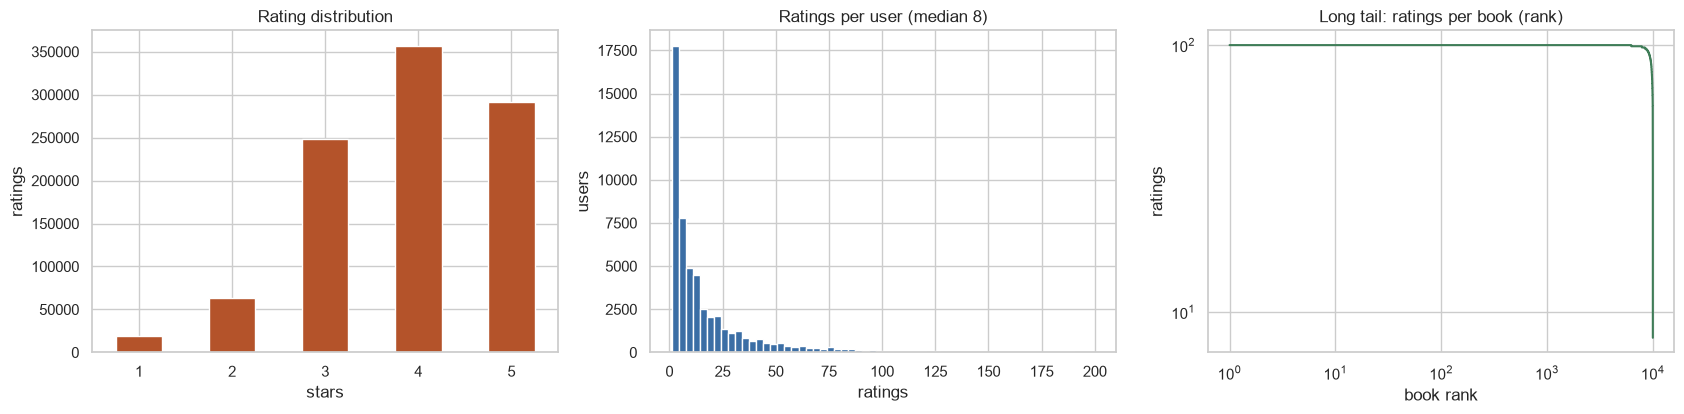

In [4]:
n_users, n_items = ratings.user_id.nunique(), len(books)
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"User x book matrix sparsity: {sparsity:.4%}  (only {1 - sparsity:.3%} of cells are known)")
print(f"Mean rating: {ratings.rating.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ratings.rating.round().astype(int).value_counts().sort_index().plot.bar(ax=ax[0], color="#b4532a")
ax[0].set(title="Rating distribution", xlabel="stars", ylabel="ratings")
ax[0].tick_params(axis="x", rotation=0)

per_user = ratings.groupby("user_id").size()
per_user.plot.hist(bins=60, ax=ax[1], color="#3b6ea5")
ax[1].set(title=f"Ratings per user (median {per_user.median():.0f})", xlabel="ratings", ylabel="users")

per_book = ratings.groupby("book_id").size().sort_values(ascending=False).to_numpy()
ax[2].plot(np.arange(1, len(per_book) + 1), per_book, color="#3f7d58")
ax[2].set(xscale="log", yscale="log", title="Long tail: ratings per book (rank)", xlabel="book rank", ylabel="ratings")
plt.tight_layout(); plt.show()

**Observations**
* Ratings skew positive (4★ is the most common), which is typical of voluntary ratings. Because of this, "liked" means **≥ 4★** in the ranking evaluation.
* Half the users have rated 8 or fewer books, so the data is **very sparse**. Matrix factorisation suits this, and cold start matters.
* Ratings follow a long tail. A pure popularity model will look strong on accuracy but recommend the same books to everyone. We therefore also track **catalogue coverage**.

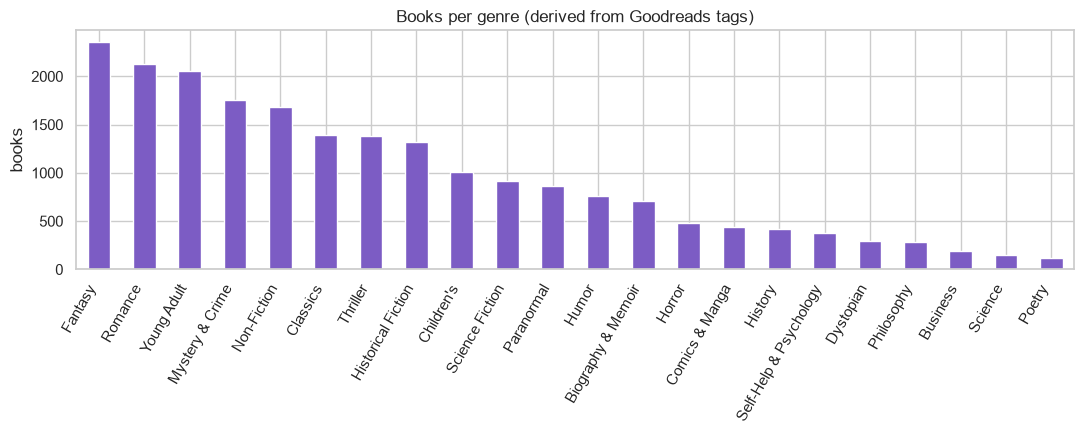

In [5]:
genre_counts = pd.Series([g for gs in books.genres for g in gs]).value_counts()
plt.figure(figsize=(11, 4.5))
genre_counts.plot.bar(color="#7c5cc4")
plt.title("Books per genre (derived from Goodreads tags)"); plt.ylabel("books"); plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

## 3. Train / test split
We hold out **20% of each user's ratings** (users with fewer than 5 ratings stay entirely in training). A purely random split would leave some users with nothing in training. A per-user split guarantees that every test user has a profile to recommend from.

In [6]:
train_df, test_df = data.split_per_user(ratings)
trainset, testset = pipeline.to_trainset(train_df), pipeline.to_testset(test_df)
print(f"train: {len(train_df):,} ratings   test: {len(test_df):,} ratings   test users: {test_df.user_id.nunique():,}")

train: 806,226 ratings   test: 173,252 ratings   test users: 35,659


## 4. Collaborative filtering: SVD

SVD (Funk-style matrix factorisation, as popularised by the Netflix Prize) models a rating as

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$$

where $b_u$ and $b_i$ are user and book biases, and $p_u, q_i \in \mathbb{R}^k$ are latent "taste" vectors learned by stochastic gradient descent with L2 regularisation.

### 4a. Hyper-parameter tuning
Randomised search with 3-fold cross-validation on a 300k-rating sample of the training data.

In [7]:
t0 = time.time()
svd_params, tuning = pipeline.tune_svd(train_df)
print(f"best params: {svd_params}   ({time.time() - t0:.0f}s)")
display(tuning.head(8))

best params: {'n_factors': 50, 'n_epochs': 40, 'lr_all': 0.005, 'reg_all': 0.08}   (28s)


,param_n_factors,param_n_epochs,param_lr_all,param_reg_all,mean_test_rmse,mean_test_mae
0,50,40,0.005,0.08,0.880525,0.694827
1,100,20,0.010,0.10,0.881367,0.697066
2,50,30,0.005,0.08,0.881535,0.697492
3,50,30,0.010,0.05,0.884603,0.694995
4,50,20,0.005,0.10,0.884902,0.703134
5,150,20,0.010,0.08,0.885158,0.700797
6,200,30,0.010,0.08,0.885350,0.700884
7,100,30,0.010,0.05,0.885863,0.698141


### 4b. Compare against baselines on the held-out ratings

,model,RMSE,MAE,train_seconds
0,Random (NormalPredictor),1.322365,1.054794,2.4
1,Baseline (user + item bias),0.837826,0.661472,2.7
2,SVD (original notebook params),0.836143,0.652176,14.2
3,SVD (tuned),0.824147,0.641499,21.8


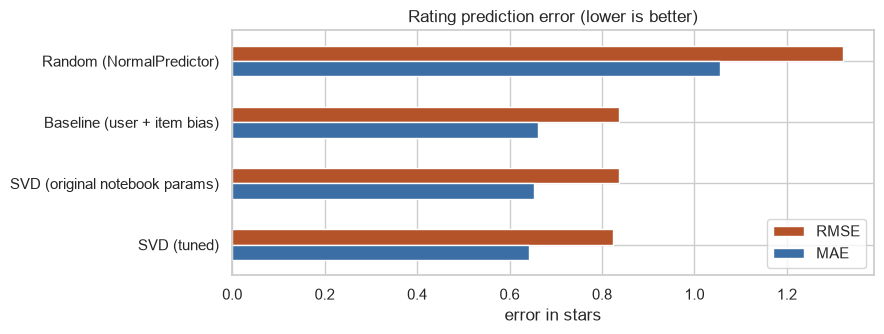

In [8]:
rating_table, fitted = pipeline.benchmark_rating_models(trainset, testset, svd_params)
display(rating_table)

ax = rating_table.set_index("model")[["RMSE", "MAE"]].plot.barh(figsize=(9, 3.5), color=["#b4532a", "#3b6ea5"])
ax.set(title="Rating prediction error (lower is better)", xlabel="error in stars", ylabel="")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

* A model that predicts random ratings scores RMSE ≈ 1.32. Biases alone (some books and some readers are simply rated higher) bring this down to ≈ 0.84.
* The **tuned SVD** gives the lowest error. Here tuning favoured **fewer factors with stronger regularisation**, because most users have very few ratings and a larger model overfits them.

In [9]:
cf = pipeline.export_cf(fitted["SVD (tuned)"], trainset, len(books))
print("exported arrays:", {k: getattr(v, "shape", v) for k, v in cf.items() if k not in ("user_row",)})

exported arrays: {'mu': (), 'bi': (10000,), 'qi': (10000, 50), 'bu': (53424,), 'pu': (53424, 50), 'user_ids': (53424,)}


### 4c. Item-kNN on implicit feedback ("readers of X also read Y")
SVD is trained to predict **how many stars** a reader gives. A recommender must predict **which books** they will pick up next, and those are different tasks. Item-kNN uses only *who read what*:

$$\text{sim}(i,j) = \frac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|}}$$

We keep the 100 strongest neighbours of each book. A reader's score for book $j$ is $\sum_i w_{ui}\,\text{sim}(i,j)$, where $w_{ui}$ is the same star weight used by the content model. No retraining is needed for new readers.

In [10]:
KNN_NEIGHBOURS = 100
knn = scoring.build_item_knn(train_df, len(books), KNN_NEIGHBOURS)
print(f"item-kNN: {knn.nnz:,} neighbour links ({KNN_NEIGHBOURS} per book)")

item-kNN: 998,720 neighbour links (100 per book)


## 5. Content-based model
Each book becomes a vector of **TF-IDF weighted Goodreads tags** (term frequency = log(1 + times tagged)) plus **one-hot authors**. Rows are L2-normalised, so the dot product of two rows is their cosine similarity.

A reader's **taste profile** is the rating-weighted sum of the books they have read. The weights follow Goodreads' own scale (3★ = "liked it"): 5★ → +2.5, 4★ → +1.5, 3★ → +0.5, 2★ → −0.5, 1★ → −1.5. Books are scored by cosine similarity to that profile.

This model works for **any** book with tags, even if few people have rated it, and it is easy to explain.

In [11]:
content, feature_names = features.build_content_matrix(books, book_tags)
print(f"content matrix: {content.shape[0]:,} books x {content.shape[1]:,} features ({content.nnz:,} non-zeros)")

def show_similar(title_part, n=6):
    i = books.index[books.title.str.contains(title_part, regex=False)][0]
    cb = (content @ content[i].T).toarray().ravel()
    co = knn[i].toarray().ravel()
    blend = scoring.item_similarity(knn, content, i)
    out = []
    for name, s in [("content (tags)", cb), ("co-reading (kNN)", co), ("blend (used in app)", blend)]:
        top = scoring.top_n(s, n, exclude=[i])
        out.append(pd.Series(books.title[top].str.slice(0, 45).to_numpy(), name=name))
    print("Similar to:", books.title[i])
    display(pd.concat(out, axis=1))

show_similar("The Hunger Games (The Hunger Games, #1)")
show_similar("Pride and Prejudice")

content matrix: 10,000 books x 13,696 features (553,083 non-zeros)
Similar to: The Hunger Games (The Hunger Games, #1)


,content (tags),co-reading (kNN),blend (used in app)
0,"Catching Fire (The Hunger Games, #2)","Catching Fire (The Hunger Games, #2)","Catching Fire (The Hunger Games, #2)"
1,"Mockingjay (The Hunger Games, #3)",Harry Potter and the Sorcerer's Stone (Harry,"Mockingjay (The Hunger Games, #3)"
2,The Hunger Games Trilogy Boxset (The Hunger G,The Help,"Twilight (Twilight, #1)"
3,"The Maze Runner (Maze Runner, #1)","Twilight (Twilight, #1)",Harry Potter and the Sorcerer's Stone (Harry
4,Gregor and the Prophecy of Bane (Underland Ch,To Kill a Mockingbird,Brave New World
5,Gregor and the Curse of the Warmbloods (Under,"Mockingjay (The Hunger Games, #3)","Divergent (Divergent, #1)"


Similar to: Pride and Prejudice


,content (tags),co-reading (kNN),blend (used in app)
0,Emma,Jane Eyre,Emma
1,Persuasion,The Catcher in the Rye,Sense and Sensibility
2,Northanger Abbey,Sense and Sensibility,Persuasion
3,Mansfield Park,Memoirs of a Geisha,Jane Eyre
4,The Complete Novels,To Kill a Mockingbird,Wuthering Heights
5,Lady Susan,The Great Gatsby,The Catcher in the Rye


The **content** column finds books that are *described* alike (same series, same author, same tags). The **co-reading** column finds books *read by the same people*, which can link across genres. The **blend** gives the "Readers who liked this also liked" row in the app.

## 6. Top-K ranking evaluation

### Why the first notebook's Precision@10 = 0.68 / Recall@10 = 0.82 was misleading
That function sorted only each user's **≈4 held-out test books** and took the "top 10". With fewer than 10 candidates, every held-out book is always "recommended", so recall is close to 1 by construction. It never tested whether the model can find good books among **10,000** candidates.

### Protocol used here
For each test user we score **every book they have not rated in training**, take the top 10, and count how many of their held-out **≥ 4★** books appear.
* **Precision@10 / Recall@10**: hits ÷ 10 and hits ÷ number of liked held-out books
* **NDCG@10**: like recall, but a hit at rank 1 counts more than a hit at rank 10
* **HitRate@10**: share of users with at least one hit
* **Coverage**: share of the catalogue that is recommended to anyone

Users are split into **1,500 validation users**, used only to tune the hybrid weights, and **3,000 test users**, used for the numbers we report.

best hybrid weights on validation users: {'alpha': 0.4, 'svd_weight': 0.25, 'pop_weight': 0.0}


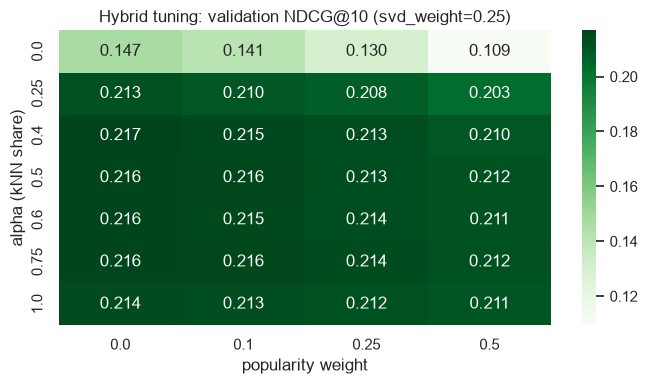

In [12]:
ev = pipeline.RankingEvaluator(train_df, test_df, cf, knn, content, books["ratings_count"].to_numpy())
weights, hybrid_grid = ev.tune_hybrid()
print("best hybrid weights on validation users:", weights)

heat = hybrid_grid[hybrid_grid.svd_weight == weights["svd_weight"]].pivot(
    index="alpha", columns="pop_weight", values=f"NDCG@{TOP_K}")
plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Greens")
plt.title(f"Hybrid tuning: validation NDCG@10 (svd_weight={weights['svd_weight']})"); plt.xlabel("popularity weight"); plt.ylabel("alpha (kNN share)")
plt.tight_layout(); plt.show()

The hybrid score for a user is

$$\text{score}_i = \alpha\, z(\text{kNN}_{ui}) + (1-\alpha)\, z(\text{content}_{ui}) + w_{svd}\, z(\hat r^{SVD}_{ui}) + w_{pop}\, z(\log \text{pop}_i)$$

where $z(\cdot)$ standardises each signal across the catalogue so that all of them are on the same scale. Popularity is the Goodreads-wide rating count from `books.csv`.

,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,AvgPopularityPct
model,,,,,,
Most Popular,0.0005,0.0002,0.0005,0.0030,0.0029,0.9995
SVD (explicit ratings),0.0005,0.0012,0.0008,0.0043,0.0110,0.4044
Content-based (tags + author),0.0624,0.1957,0.1609,0.3933,0.7421,0.5642
Item-kNN (implicit co-reading),0.0841,0.2619,0.2273,0.4857,0.7360,0.5076
Hybrid (tuned),0.0851,0.2625,0.2284,0.4897,0.7542,0.5149


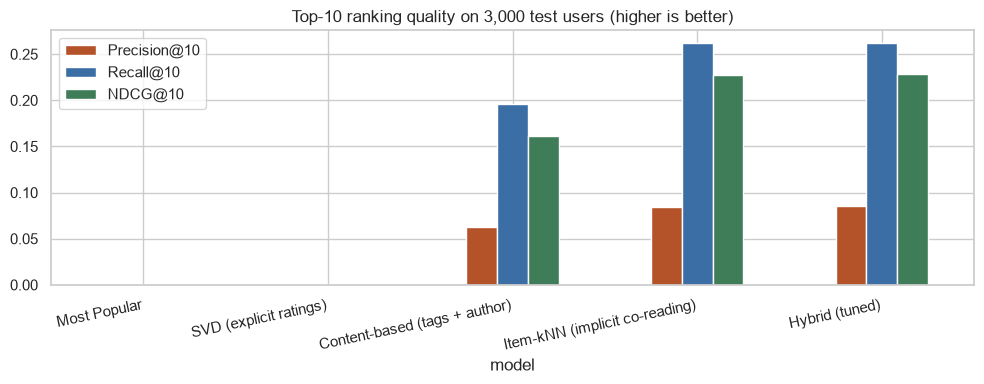

In [13]:
methods = ["Most Popular", "SVD (explicit ratings)", "Content-based (tags + author)",
           "Item-kNN (implicit co-reading)", "Hybrid (tuned)"]
rows = [{"model": m, **ev.evaluate(ev.test_users, m, weights)} for m in methods]
ranking_table = pd.DataFrame(rows).set_index("model")
display(ranking_table.style.format("{:.4f}").highlight_max(color="#cfe8d7"))

ranking_table[[f"Precision@{TOP_K}", f"Recall@{TOP_K}", f"NDCG@{TOP_K}"]].plot.bar(figsize=(10, 4), rot=0, color=["#b4532a", "#3b6ea5", "#3f7d58"])
plt.title("Top-10 ranking quality on 3,000 test users (higher is better)"); plt.xticks(rotation=12, ha="right"); plt.tight_layout(); plt.show()

**Reading the results**
* A random ranking would score Precision@10 ≈ 0.0004.
* **Most Popular is no better than random here.** This is a property of the dataset: Goodbooks-10k was **sampled to about 100 ratings per book** (see the check below). A bestseller is therefore no more likely to be in a user's history than an obscure book. On most real systems popularity is a strong baseline; here it is not.
* **SVD alone ranks poorly** even though it has the best RMSE. Predicting *how many stars* is a different task from predicting *which books* someone reads (Cremonesi et al., 2010). SVD ranks books that everyone rates highly first, whether or not this reader would pick them up.
* **Content-based** works well because readers follow authors and series.
* **Item-kNN** is the strongest single model, because co-reading is exactly the signal the task measures.
* The **tuned hybrid** is the best overall. It blends kNN and content and adds a small amount of SVD, which helps once it is combined with the other signals. It also keeps catalogue coverage high (about 74% of books get recommended to someone).

In [14]:
per_book = ratings.groupby("book_id").size()
print("ratings per book in the dataset:", per_book.describe()[["min", "25%", "50%", "75%", "max"]].to_dict())

ratings per book in the dataset: {'min': 8.0, '25%': 99.0, '50%': 100.0, '75%': 100.0, 'max': 100.0}


## 7. Cold start: recommending for a brand-new reader
Item-kNN and the content model work for a new reader immediately, because they only need the reader's ratings. The SVD rating model, however, has no $p_u$ for them. Instead of retraining, we **fold them in**: with the book vectors $q_i$ and biases fixed, we solve the ridge regression for their $b_u$ and $p_u$ from the few books they rated:

$$\min_{b_u,p_u} \sum_{i \in R(u)} (r_{ui} - \mu - b_i - b_u - p_u^\top q_i)^2 + \lambda (b_u^2 + \lVert p_u\rVert^2)$$

To choose λ, we treat known validation users as new readers. Their vectors are rebuilt from training ratings only, and we measure RMSE on their held-out ratings.

In [15]:
fold_reg, fold_grid = pipeline.tune_fold_in(cf, train_df, test_df, ev.val_users[:800])
display(fold_grid)
print(f"chosen lambda = {fold_reg}  (the trained SVD gets RMSE {rating_table.set_index('model').loc['SVD (tuned)', 'RMSE']:.4f} on all users)")

,reg,RMSE
0,0.1,0.921380
1,0.5,0.858132
2,1.0,0.837533
3,2.0,0.823478
4,5.0,0.815881
5,10.0,0.817661
6,20.0,0.825248


chosen lambda = 5.0  (the trained SVD gets RMSE 0.8241 on all users)


In the app, a new reader with no ratings gets the best books in their chosen genres. Once they rate books, the full hybrid takes over, and the SVD weight grows with confidence $n/(n+3)$, where $n$ is the number of ratings.

## 8. Export the final model and try the live engine
For the deployed model we retrain SVD (with the tuned hyper-parameters) and item-kNN on **all** ratings, then save plain NumPy/SciPy arrays. The web app does not need Surprise installed.

In [16]:
from surprise import SVD
final = SVD(**svd_params, random_state=RANDOM_STATE)
full_trainset = pipeline.to_trainset(ratings)
final.fit(full_trainset)
cf_full = pipeline.export_cf(final, full_trainset, len(books))
knn_full = scoring.build_item_knn(ratings, len(books), KNN_NEIGHBOURS)

meta = json.loads(open("artifacts/meta.json", encoding="utf-8").read()) if __import__("os").path.exists("artifacts/meta.json") else {}
meta.update({
    "svd_params": svd_params,
    "svd_tuning": tuning.to_dict("records"),
    "rating_metrics": rating_table.to_dict("records"),
    "ranking_metrics": ranking_table.reset_index().to_dict("records"),
    "hybrid": weights,
    "knn_neighbours": KNN_NEIGHBOURS,
    "hybrid_grid": hybrid_grid.to_dict("records"),
    "fold_in": {"reg": fold_reg, "grid": fold_grid.to_dict("records")},
})
meta.setdefault("dataset", {}).update({
    "n_ratings": int(len(ratings)), "n_users": int(n_users), "n_books": int(n_items),
    "n_train": int(len(train_df)), "n_test": int(len(test_df)), "sparsity": float(sparsity),
    "rating_distribution": {str(k): int(v) for k, v in ratings.rating.round().astype(int).value_counts().sort_index().items()},
    "n_content_features": int(content.shape[1]),
})
meta["ranking_protocol"] = {"k": TOP_K, "relevance_threshold": RELEVANCE_THRESHOLD,
                            "n_test_users": int(len(ev.test_users)), "n_val_users": int(len(ev.val_users))}
meta["genres"] = list(GENRES)
pipeline.save_artifacts(cf_full, knn_full, content, feature_names, books, ratings, meta)
print("saved to artifacts/")

saved to artifacts/


In [17]:
from recsys.engine import Recommender
rec = Recommender()

def show(items, cols=("title", "authors", "match", "predicted_rating", "reason")):
    df = pd.DataFrame(items)
    df["reason"] = df["reason"].apply(lambda r: r["text"] if isinstance(r, dict) else r)
    display(df[[c for c in cols if c in df]])

uid = 314
p = rec.user_profile(uid)
print(f"Reader {uid}: {p['n_ratings']} ratings, favourite genres {p['top_genres']}, taste tags {p['taste_tags'][:8]}")
print("Their top-rated books:", [b["title"] for b in p["rated"][:5]])
show(rec.recommend_user(uid, n=10))

Reader 314: 181 ratings, favourite genres ['Young Adult', 'Fantasy', 'Science Fiction'], taste tags ['fantasy', 'young-adult', 'fiction', 'adventure', 'ya', 'science-fiction', 'sci-fi', 'action']
Their top-rated books: ['The Hunger Games (The Hunger Games, #1)', 'The Fault in Our Stars', 'The Help', 'The Book Thief', 'The Count of Monte Cristo']


,title,authors,match,predicted_rating,reason
0,"Harry Potter and the Deathly Hallows (Harry Potter, #7)","J.K. Rowling, Mary GrandPré",69,3.91,"Because you liked Ender's Game (Ender's Saga, #1)"
1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",67,3.83,Because you liked The Lightning Thief (Percy Jackson and the Olymp...
2,Lord of the Flies,William Golding,70,3.89,Because you liked The Scarlet Letter
3,The Secret Life of Bees,Sue Monk Kidd,58,3.78,Because you liked The Help
4,"The Golden Compass (His Dark Materials, #1)",Philip Pullman,85,3.64,"Because you liked Ender's Game (Ender's Saga, #1)"
5,Fahrenheit 451,Ray Bradbury,69,3.84,"Because you liked The Giver (The Giver, #1)"
6,Life of Pi,Yann Martel,47,3.65,Because you liked Water for Elephants
7,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",68,3.83,"Because you liked The Giver (The Giver, #1)"
8,"A Wrinkle in Time (A Wrinkle in Time Quintet, #1)",Madeleine L'Engle,74,3.94,"Because you liked The Giver (The Giver, #1)"
9,1984,"George Orwell, Erich Fromm, Celâl Üster",63,3.95,Because you liked The Road


### A brand-new reader who loved three fantasy classics and disliked one romance

In [18]:
title_to_id = dict(zip(books.title, books.book_id))
new_reader = {
    title_to_id["The Hobbit"]: 5,
    title_to_id["A Game of Thrones (A Song of Ice and Fire, #1)"]: 5,
    title_to_id["The Name of the Wind (The Kingkiller Chronicle, #1)"]: 4,
    title_to_id["Twilight (Twilight, #1)"]: 1,
}
show(rec.recommend_new(new_reader, n=10))

,title,authors,match,predicted_rating,reason
0,"The Two Towers (The Lord of the Rings, #2)",J.R.R. Tolkien,83,4.35,Because you liked The Hobbit
1,"The Lord of the Rings (The Lord of the Rings, #1-3)",J.R.R. Tolkien,90,4.42,Because you liked The Hobbit
2,"The Return of the King (The Lord of the Rings, #3)",J.R.R. Tolkien,83,4.39,Because you liked The Hobbit
3,"A Clash of Kings (A Song of Ice and Fire, #2)",George R.R. Martin,100,4.30,"Because you liked A Game of Thrones (A Song of Ice and Fire, #1)"
4,"A Storm of Swords (A Song of Ice and Fire, #3)",George R.R. Martin,97,4.38,"Because you liked A Game of Thrones (A Song of Ice and Fire, #1)"
5,"The Fellowship of the Ring (The Lord of the Rings, #1)",J.R.R. Tolkien,81,4.32,Because you liked The Hobbit
6,"A Feast for Crows (A Song of Ice and Fire, #4)",George R.R. Martin,97,4.01,"Because you liked A Game of Thrones (A Song of Ice and Fire, #1)"
7,"A Dance with Dragons (A Song of Ice and Fire, #5)",George R.R. Martin,96,4.08,"Because you liked A Game of Thrones (A Song of Ice and Fire, #1)"
8,"The Wise Man's Fear (The Kingkiller Chronicle, #2)",Patrick Rothfuss,73,4.40,"Because you liked The Name of the Wind (The Kingkiller Chronicle, #1)"
9,"The Golden Compass (His Dark Materials, #1)",Philip Pullman,38,3.88,Because you liked The Hobbit


## 9. Conclusions
| | |
|---|---|
| **Problem type** | Recommender system: rating prediction + top-K ranking (not classification) |
| **Best rating predictor** | Tuned SVD (lowest RMSE / MAE of all models) |
| **Best ranker** | Hybrid of item-kNN + content + SVD, with weights tuned on validation users |
| **Cold start** | Genre-based start → kNN + content from the first rating → SVD fold-in, with the λ tuned |
| **Explainability** | Every recommendation cites the most similar book the reader loved, or the tags they share |

**Fixed from the first version:** the book-ID join bug, duplicate ratings, an evaluation that inflated recall, and unused data (tags, to-read shelves, authors now feed the content model and the reader profiles).

**Dataset caveat:** Goodbooks-10k caps each book at about 100 sampled ratings, so it cannot show popularity effects. Real-world numbers would differ.

**Possible extensions:** learned implicit models (ALS / BPR, also using `to_read.csv`), SVD++, a learned (e.g. gradient-boosted) re-ranker, and diversity-aware re-ranking (MMR).

**Run the web app:** `run.bat` (or `python app.py`), then open http://127.0.0.1:8000